# BT4012 Kaggle competition: detecting illicit Bitcoin transactions

**Student:** e1156285 &nbsp;·&nbsp; **Final model:** two tree models averaged, with extra weight on recent data (half-life 4) &nbsp;·&nbsp; **Public ROC-AUC:** 0.95471

This notebook rebuilds my best Kaggle submission from the raw competition files. It runs from top to bottom in a few minutes on a laptop and writes the same CSV file that was uploaded to Kaggle.

**What the notebook does, in order**

1. **Setup**: loads the code libraries and fixes the settings that make the run repeatable.
2. **Load the data**: reads the training, test, payment-link and sample-submission files.
3. **Data checks**: missing values, file alignment and how the share of illicit transactions changes over time.
4. **Feature preparation**: removes six "calendar" features, explains the graph features we tested, and builds the recency weights.
5. **The two models**: XGBoost and LightGBM with light "brakes", averaged 50/50.
6. **Validation**: 15 forward-in-time "practice exams" comparing a simple baseline, the two-model average, and different recency strengths.
7. **Final model**: trains on every labelled training transaction and scores the test set.
8. **Submission file**: builds `index,target`, checks it and saves it.
9. **Second final selection** (optional): the average of the half-life 3, 4 and 5 models.

**How to run**

1. Put the competition files in `Data Set/` exactly as listed in `README.md`.
2. Install the libraries: `pip install -r requirements.txt`.
3. In Jupyter, choose *Kernel → Restart Kernel and Run All Cells*.

**Key terms in plain language**

| Term | Meaning |
|---|---|
| Model | A recipe that learns from labelled examples how the 165 numbers relate to "illicit", then scores new transactions |
| ROC-AUC | Pick one illicit and one licit transaction at random: the chance the model scores the illicit one higher. 0.5 = coin toss, 1.0 = perfect |
| Decision tree | A flowchart of yes/no questions about the numbers |
| Gradient boosting | Many small trees built one after another, each fixing the previous trees' mistakes |
| Regularisation ("brakes") | Limits that stop a model trusting patterns seen in too few examples |
| Recency weighting | Recent time steps count more during training; with half-life 4, step 31 counts half as much as step 35 |
| Practice exam | Hide later time steps, learn from earlier ones, and check how well the later ones are ranked |

## 1. Setup

A **library** is ready-made code someone else wrote. We use `pandas` for tables, `numpy` for maths, `matplotlib` for charts, `scikit-learn` for the baseline model and the ROC-AUC score, and `xgboost` and `lightgbm` for the two final models.

Two settings make the run repeatable: a fixed **random seed** (the models' "dice rolls" come out the same every time) and a fixed number of CPU **threads** (2). With both fixed, the notebook reproduces the uploaded file exactly.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
import lightgbm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Data Set"
OUTPUT_DIR = PROJECT_DIR / "submissions"
OUTPUT_DIR.mkdir(exist_ok=True)

SEED = 42             # fixed random seed: same result on every run
THREADS = 2           # fixed CPU threads: needed to match the uploaded file exactly
FINAL_HALF_LIFE = 4   # recency strength of the final model (chosen in Section 6)
NOTEBOOK_START = time.time()

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__)

pandas 2.3.3 | numpy 2.5.3 | scikit-learn 1.9.1 | xgboost 3.2.0 | lightgbm 4.7.0


## 2. Load the data

- **Training file**: transactions from time steps 1–35. Each has a label: `1` = illicit, `0` = licit, or blank = unknown.
- **Test file**: transactions from time steps 36–49, without labels. These are the ones Kaggle scores.
- **Payment links** (`TXS Edgelist.csv`): pairs of transactions where money moved from one to the other.
- **Sample submission**: the row order and format Kaggle expects (`index,target`).

Each transaction has 165 anonymised numbers (`feat_1` to `feat_165`). Numbers 1–93 describe the transaction itself; numbers 94–165 summarise its neighbours in the payment network.

In [2]:
train = pd.read_csv(DATA_DIR / "Train Data.csv")
test = pd.read_csv(DATA_DIR / "Test Data.csv")
edges = pd.read_csv(DATA_DIR / "TXS Edgelist.csv")
sample = pd.read_csv(DATA_DIR / "Sample Submission" / "BT4012 Competition Submission.csv")

FEATURES = [f"feat_{i}" for i in range(1, 166)]

labels = pd.to_numeric(train["label"], errors="coerce")   # blank labels become NaN (unknown)
known = train.loc[labels.notna()].copy()                   # labelled rows: the only rows we learn from
known["label"] = labels.loc[labels.notna()].astype(int)
unknown = train.loc[labels.isna()]

overview = pd.DataFrame(
    {
        "Rows": [len(train), len(known), int(known["label"].sum()), len(unknown), len(test), len(edges)],
        "Time steps": [
            f"{train.time_step.min()}-{train.time_step.max()}", f"{known.time_step.min()}-{known.time_step.max()}",
            "", "", f"{test.time_step.min()}-{test.time_step.max()}", "",
        ],
    },
    index=["Training transactions", "  labelled", "    of which illicit", "  unknown label",
           "Test transactions", "Payment links"],
)
overview

,Rows,Time steps
Training transactions,141772,1-35
labelled,31235,1-35
of which illicit,3644,
unknown label,110537,
Test transactions,15329,36-49
Payment links,234355,


## 3. Data checks

### 3.1 Missing values and file alignment

We check three things: that no feature values are missing, that the only gaps are the unknown labels, and that the test file lines up one-to-one with the sample submission (so every prediction lands on the right row).

In [3]:
checks = {
    "Missing feature values (training)": int(train[FEATURES].isna().sum().sum()),
    "Missing feature values (test)": int(test[FEATURES].isna().sum().sum()),
    "Unknown labels (training)": int(labels.isna().sum()),
    "Test rows = sample rows": len(test) == len(sample),
    "Same index values in test and sample": set(test["index"]) == set(sample["index"]),
    "Duplicate transaction IDs (train + test)": int(pd.concat([train.txId, test.txId]).duplicated().sum()),
}
pd.Series(checks, name="Result").to_frame()

,Result
Missing feature values (training),0
Missing feature values (test),0
Unknown labels (training),110537
Test rows = sample rows,True
Same index values in test and sample,True
Duplicate transaction IDs (train + test),0


No feature values are missing and the features arrive already scaled, so no filling or rescaling is needed. The only gap is the label of the unknown transactions.

**Why we do not use the unknown rows.** During development we tried four ways of using them: treating them as licit, letting a model guess their labels (pseudo-labels), spreading labels to nearby transactions, and learning compressed features from all rows with an autoencoder. All four lowered our practice-exam scores. Using them is like grading homework nobody has marked: wrong guesses teach the model wrong answers. The final model therefore learns from the labelled rows only.

### 3.2 How the share of illicit transactions changes over time

The chart shows, for each training time step, how many labelled transactions there are and what share is illicit. The share moves around a lot from step to step. The bigger change comes later: a large dark market was shut down at step 43, inside the test period, after which illicit activity drops sharply. Our training data contains nothing like that event, which is the main difficulty of this competition.

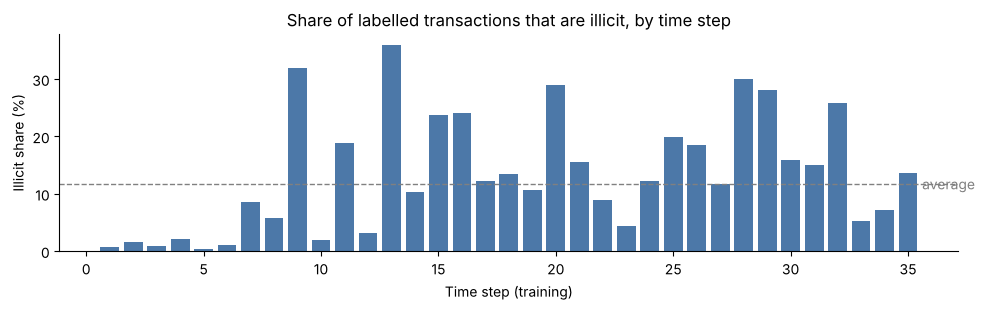

Overall illicit share: 11.7% (lowest step 0.4%, highest 36.0%)


In [4]:
by_step = known.groupby("time_step")["label"].agg(labelled="size", illicit="sum")
by_step["illicit share (%)"] = 100 * by_step["illicit"] / by_step["labelled"]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(by_step.index, by_step["illicit share (%)"], color="#4C78A8")
ax.axhline(100 * known["label"].mean(), color="grey", linestyle="--", linewidth=1)
ax.text(35.6, 100 * known["label"].mean(), "average", va="center", color="grey")
ax.set_xlabel("Time step (training)")
ax.set_ylabel("Illicit share (%)")
ax.set_title("Share of labelled transactions that are illicit, by time step")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Overall illicit share: {100 * known['label'].mean():.1f}% "
      f"(lowest step {by_step['illicit share (%)'].min():.1f}%, highest {by_step['illicit share (%)'].max():.1f}%)")

## 4. Feature preparation

### 4.1 Removing "calendar" features (XGBoost only)

Some features rise and fall almost exactly with the time step. They act like a date printed on each page: a model could learn "early dates mean more fraud", which tells us nothing about future dates. We measure each feature's **rank correlation** with the time step (Spearman: 1 = they always move up together) and remove features above 0.9 from the XGBoost model.

The list is always computed from the rows the model is trained on, never from the test rows or from later time steps. LightGBM keeps all 165 features, so the two models look at the data from slightly different angles, which helps their average.

In [5]:
def time_correlation(rows):
    # Spearman correlation = ordinary correlation between ranks
    return rows[FEATURES].rank().corrwith(rows["time_step"].rank())


def find_calendar_features(rows, threshold=0.9):
    corr = time_correlation(rows)
    return sorted(corr[corr.abs() > threshold].index, key=lambda c: int(c.split("_")[1]))


calendar = find_calendar_features(known)
print(f"{len(calendar)} calendar features removed from XGBoost:", calendar)
time_correlation(known)[calendar].round(3).rename("rank correlation with time step").to_frame()

6 calendar features removed from XGBoost: ['feat_100', 'feat_101', 'feat_103', 'feat_136', 'feat_137', 'feat_139']


,rank correlation with time step
feat_100,0.983
feat_101,0.998
feat_103,0.990
feat_136,0.993
feat_137,0.910
feat_139,0.959


### 4.2 Graph features: tested, not used

The payment links turn the data into a network, so we tested network features: **node degree** (how many links a transaction has), neighbours' degrees, triangles, clustering, two-step reach and **PageRank** (how "central" a transaction is). We also tried graph neural networks (GCN and GraphSAGE), which learn directly from the links. During development (see `archive/e1156285_development_log.ipynb`) none of them beat the plain 165 features on the practice exams: adding all network features lowered the average by about 0.005, and degrees alone by about 0.002. The final model therefore does not use them.

Two reasons explain this. Features 94–165 already summarise each transaction's neighbours. And the network is full of holes, as the cell below shows: most links that touch a test transaction lead to a transaction that is not in any file, so network measures for test rows are built from incomplete information.

In [6]:
in_files = set(train["txId"]) | set(test["txId"])
test_ids = set(test["txId"])

touches_test = edges[edges["txId1"].isin(test_ids) | edges["txId2"].isin(test_ids)]
other_end = np.where(touches_test["txId1"].isin(test_ids), touches_test["txId2"], touches_test["txId1"])
missing_share = (~pd.Series(other_end).isin(in_files)).mean()

linked_test = len(test_ids & (set(edges["txId1"]) | set(edges["txId2"])))
print(f"Links touching a test transaction: {len(touches_test):,}")
print(f"Share whose other end is missing from the files: {missing_share:.0%}")
print(f"Test transactions with at least one link: {linked_test:,} of {len(test):,}")

Links touching a test transaction: 36,969
Share whose other end is missing from the files: 66%
Test transactions with at least one link: 15,329 of 15,329


### 4.3 Recency weights

**Recency weighting** lets recent training transactions count more than old ones. Each transaction gets the weight

$$\text{weight} = 0.5^{(\text{latest step} - \text{its step}) / \text{half-life}}$$

With a half-life of 4, a transaction from step 31 counts half as much as one from step 35, and one from step 27 a quarter as much. It works like a weather forecaster who trusts last week more than last year. The weights are rescaled to average 1, so only their relative sizes matter.

Stronger recency has a cost: the model effectively learns from fewer examples. The table shows this with the **effective number of rows** (how many equally weighted rows would carry the same amount of information).

In [7]:
def recency_weights(time_steps, half_life):
    # Weight for each training row; None means no recency weighting (all rows count equally)
    if half_life is None:
        return np.ones(len(time_steps))
    age = time_steps.max() - time_steps
    weights = 0.5 ** (age / half_life)
    return (weights / weights.mean()).to_numpy()


def effective_rows(weights):
    return weights.sum() ** 2 / (weights ** 2).sum()


rows = []
for half_life in [None, 7, 5, 4, 3]:
    w = recency_weights(known["time_step"], half_life)
    illicit = known["label"].to_numpy() == 1
    rows.append({
        "Half-life": "none" if half_life is None else half_life,
        "Weight on steps 29-35 (%)": round(100 * w[known["time_step"].to_numpy() >= 29].sum() / w.sum(), 1),
        "Effective rows": round(effective_rows(w)),
        "Effective illicit rows": round(effective_rows(w[illicit])),
    })
pd.DataFrame(rows).set_index("Half-life")

,Weight on steps 29-35 (%),Effective rows,Effective illicit rows
Half-life,,,
none,19.3,31235,3644
7,55.4,15107,2279
5,67.5,10969,1790
4,75.7,8770,1488
3,85.2,6593,1146


## 5. The two models

Both models are **gradient boosting** models: they build small decision trees one after another, each new tree fixing the mistakes of the trees before it, like a relay of tutors where each one focuses on the questions the last one got wrong. We use two libraries that grow their trees slightly differently and average their scores 50/50. Like asking two doctors for an opinion, their separate mistakes partly cancel out.

| Setting | XGBoost | LightGBM | Plain meaning |
|---|---|---|---|
| Trees | 200 | 150 | How many tutors in the relay |
| Learning rate | 0.05 | 0.05 | How much each new tree may change the score (small = careful) |
| Leaves per tree | 15 | 15 | How many end points each flowchart has (small trees = simple rules) |
| Value bins | 127 | 63 | Numbers are grouped into this many buckets before splitting (coarser = less noise) |
| Brakes: smallest group per leaf | weight 1 | 5 rows | A rule must be supported by at least this much data |
| Brakes: penalty (`reg_lambda`) | 1 | 1 | Shrinks extreme scores |
| Features | 159 (no calendar features) | 165 | |

**Why light brakes?** Early on we used heavy brakes (each rule needed more data and a penalty of 10). These stopped the model from learning small groups of illicit transactions, such as small fraud rings, and lost to the lighter settings in 13 of 15 practice exams.

**Class imbalance.** Only about 12% of labelled rows are illicit. ROC-AUC judges only the ordering of scores, so we do not re-balance the classes; in development, giving illicit rows 7.6 times the weight lowered the practice-exam average by about 0.009, and creating synthetic illicit rows with SMOTE by about 0.004.

The simple **baseline** is logistic regression: it gives each feature a fixed weight and adds them up, like a checklist score.

In [8]:
def make_xgb():
    return XGBClassifier(
        n_estimators=200, learning_rate=0.05, tree_method="hist", grow_policy="lossguide",
        max_depth=0, max_leaves=15, max_bin=127, min_child_weight=1, reg_lambda=1,
        objective="binary:logistic", n_jobs=THREADS, random_state=SEED,
    )


def make_lgb():
    return LGBMClassifier(
        n_estimators=150, learning_rate=0.05, num_leaves=15, max_bin=63, min_child_samples=5,
        min_child_weight=1e-3, reg_lambda=1, objective="binary", deterministic=True,
        force_col_wise=True, verbosity=-1, n_jobs=THREADS, random_state=SEED,
    )


def train_pair(rows, half_life=FINAL_HALF_LIFE):
    # Train both models on `rows` and return a function that scores new rows
    weights = recency_weights(rows["time_step"], half_life)
    calendar_features = find_calendar_features(rows)   # computed from the training rows only
    xgb_features = [c for c in FEATURES if c not in calendar_features]
    xgb = make_xgb().fit(rows[xgb_features], rows["label"], sample_weight=weights)
    lgb = make_lgb().fit(rows[FEATURES], rows["label"], sample_weight=weights)

    def score(new_rows):
        return (0.5 * xgb.predict_proba(new_rows[xgb_features])[:, 1]
                + 0.5 * lgb.predict_proba(new_rows[FEATURES])[:, 1])

    return score


def train_baseline(rows):
    # Simple baseline: logistic regression on the standardised features
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    model.fit(rows[FEATURES], rows["label"])
    return lambda new_rows: model.predict_proba(new_rows[FEATURES])[:, 1]

## 6. Validation: 15 practice exams

**Why split by time, and why use many exams?** Ordinary cross-validation shuffles rows into random groups, so the model would learn from transactions in the same time step as the ones it is tested on. That is like practising with questions from the very paper you will sit, so we always split by time. But a single time split can also mislead: our first model scored 0.995 when tested on steps 29–35 and then 0.937 on Kaggle, because that one period happened to be easy. Averaging many exams evens out easy and hard periods.

**Practice exams.** Each exam hides the future. The model learns from steps 1 to *k* and is tested on the next 14 steps, for *k* = 7, 8, …, 21. That gives 15 exams; the local score is their average ROC-AUC. During development we checked this yardstick against real Kaggle results: it put five ordinary models in the same order as Kaggle, so it is a reliable **compass** (which direction is better), but only about a third of a local gain carried over, so it is not a reliable **ruler** (by how much).

The next cell runs the exams for the baseline, the two-model average without recency, and four recency strengths. It takes a few minutes.

In [9]:
EXAMS = [(k, k + 1, k + 14) for k in range(7, 22)]   # (last training step, first exam step, last exam step)


def practice_exams(trainer, **settings):
    results = {}
    for last_train, first_exam, last_exam in EXAMS:
        learn = known[known["time_step"] <= last_train]
        exam = known[known["time_step"].between(first_exam, last_exam)]
        score = trainer(learn, **settings)
        results[f"{first_exam}-{last_exam}"] = roc_auc_score(exam["label"], score(exam))
    return pd.Series(results)


start = time.time()
recipes = {
    "Baseline: logistic regression": (train_baseline, {}),
    "Two-model average, no recency": (train_pair, {"half_life": None}),
    "Two-model average, half-life 7": (train_pair, {"half_life": 7}),
    "Two-model average, half-life 5": (train_pair, {"half_life": 5}),
    "Two-model average, half-life 4 (final)": (train_pair, {"half_life": 4}),
    "Two-model average, half-life 3": (train_pair, {"half_life": 3}),
}
exam_results = pd.DataFrame({name: practice_exams(fn, **kw) for name, (fn, kw) in recipes.items()})
print(f"Practice exams finished in {time.time() - start:.0f} seconds")
exam_results.round(4)

Practice exams finished in 362 seconds


,Baseline: logistic regression,"Two-model average, no recency","Two-model average, half-life 7","Two-model average, half-life 5","Two-model average, half-life 4 (final)","Two-model average, half-life 3"
8-21,0.9367,0.9931,0.9933,0.9931,0.9940,0.9937
9-22,0.9354,0.9937,0.9946,0.9942,0.9943,0.9942
10-23,0.9470,0.9921,0.9926,0.9924,0.9923,0.9922
11-24,0.9372,0.9772,0.9778,0.9761,0.9735,0.9713
12-25,0.9355,0.9760,0.9759,0.9686,0.9721,0.9668
13-26,0.9275,0.9697,0.9743,0.9720,0.9729,0.9725
14-27,0.9205,0.9714,0.9758,0.9735,0.9740,0.9747
15-28,0.9203,0.9720,0.9738,0.9754,0.9706,0.9730
16-29,0.8918,0.9375,0.9373,0.9456,0.9359,0.9325
17-30,0.8813,0.9462,0.9496,0.9466,0.9395,0.9398


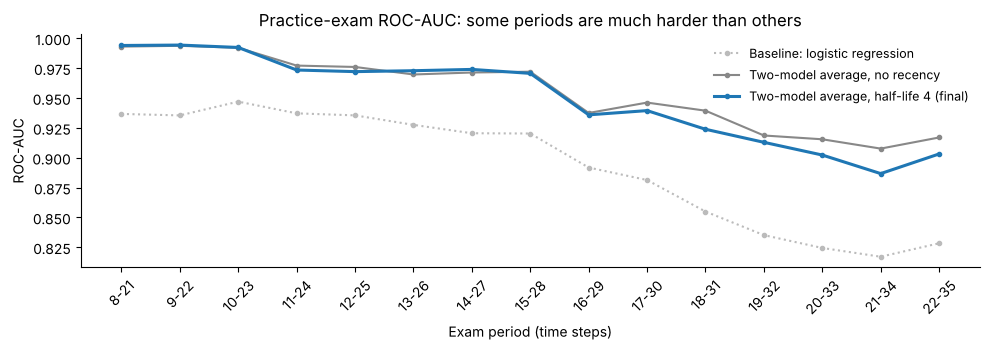

,Average of 15 exams
Baseline: logistic regression,0.8929
"Two-model average, no recency",0.9551
"Two-model average, half-life 7",0.9561
"Two-model average, half-life 5",0.9536
"Two-model average, half-life 4 (final)",0.9499
"Two-model average, half-life 3",0.9472


In [10]:
fig, ax = plt.subplots(figsize=(10, 3.6))
styles = {
    "Baseline: logistic regression": dict(color="#BBBBBB", linestyle=":"),
    "Two-model average, no recency": dict(color="#888888"),
    "Two-model average, half-life 4 (final)": dict(color="#1F77B4", linewidth=2.2),
}
for name, style in styles.items():
    ax.plot(exam_results.index, exam_results[name], marker="o", markersize=3, label=name, **style)
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("Exam period (time steps)")
ax.set_title("Practice-exam ROC-AUC: some periods are much harder than others")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

exam_results.mean().round(4).rename("Average of 15 exams").to_frame()

**Reading the practice exams.**

- The two-model average beats the logistic-regression baseline in every period, and by a wide margin in the hard ones.
- Some periods are far harder than others. These are periods where illicit behaviour changed, so patterns from earlier steps no longer fit.
- On these exams, mild recency (half-life 7) is about equal to none, and stronger recency is *worse*. That is expected: the exams all fall inside steps 1–35, where no dark market shutdown happens, so older data stays useful there and strong recency mostly throws data away.

**Why the recency strength was chosen on Kaggle.** The test period (steps 36–49) contains the shutdown, which the practice exams cannot imitate. So for this one question we let Kaggle judge, uploading one recency strength at a time. The table below records those public scores (typed in from the Kaggle leaderboard):

| Two-model average | Kaggle public ROC-AUC |
|---|---|
| No recency | 0.94701 |
| Half-life 7 | 0.94989 |
| Half-life 5 | 0.95154 |
| **Half-life 4** | **0.95471** |
| Half-life 3 | 0.95270 |

Kaggle rises with stronger recency up to a half-life of 4, then falls at 3, where the loss of data (Section 4.3) outweighs the gain in relevance. Half-life 4 is the final model. Because half-life 5 scored below both neighbours, half-life 4 was probably also a little lucky on the public 30% of test rows (by roughly 0.002), which is why Section 9 prepares a more robust second selection.

**Earlier lesson: a method can pass the exams and still fail.** A "look-alike" model that compared test transactions with each other scored 0.9713 on the practice exams but 0.87805 on Kaggle. Since then we also compare every candidate's test ranking with our best model before uploading (Section 7).

## 7. Final model: train on all labelled data and score the test set

The final model is trained on all 31,235 labelled training transactions (steps 1–35) with half-life 4 recency weights. The unknown rows are not used.

As a **safety check** we also train the same pair without recency and compare the two rankings of the test rows. A sensible change should keep most of the ranking (high agreement) while moving some rows. A ranking that turned the old one upside down would be a warning sign, as it was for the look-alike model.

In [11]:
start = time.time()
final_score = train_pair(known, half_life=FINAL_HALF_LIFE)
test_pred = final_score(test)
print(f"Final model trained and test set scored in {time.time() - start:.1f} seconds")
print("XGBoost uses", len(FEATURES) - len(find_calendar_features(known)), "features; LightGBM uses", len(FEATURES))

no_recency_pred = train_pair(known, half_life=None)(test)
top = int(round(0.06 * len(test)))   # the 6% most suspicious test rows
rank_final = pd.Series(test_pred).rank(ascending=False)
rank_old = pd.Series(no_recency_pred).rank(ascending=False)
safety = {
    "Rank agreement with no-recency model (Spearman)": round(rank_final.corr(rank_old), 3),
    f"Overlap of the top {top} most suspicious rows": f"{((rank_final <= top) & (rank_old <= top)).sum() / top:.0%}",
    "Final top rows that the old model ranked in its bottom half": f"{(rank_old[rank_final <= top] > len(test) / 2).mean():.1%}",
}
pd.Series(safety, name="Safety check").to_frame()

Final model trained and test set scored in 8.3 seconds


XGBoost uses 159 features; LightGBM uses 165


,Safety check
Rank agreement with no-recency model (Spearman),0.939
Overlap of the top 920 most suspicious rows,83%
Final top rows that the old model ranked in its bottom half,0.0%


## 8. Submission file

Kaggle expects two columns, `index` and `target`, in the same row order as the sample submission. `target` is the suspicion score between 0 and 1. The cell checks the file before saving it, then compares it with the copy uploaded to Kaggle if that copy is present.

In [12]:
submission = sample[["index"]].copy()
submission["target"] = submission["index"].map(pd.Series(test_pred, index=test["index"]))

assert list(submission.columns) == ["index", "target"]
assert len(submission) == len(sample) == 15329
assert submission["index"].equals(sample["index"]), "row order must match the sample submission"
assert submission["target"].notna().all() and submission["target"].between(0, 1).all()

final_path = OUTPUT_DIR / "submission_lowreg_pair_recent4.csv"
submission.to_csv(final_path, index=False)
print("Saved", final_path.relative_to(PROJECT_DIR))


def compare_with_uploaded(new, file_name):
    # Look for the copy that was uploaded to Kaggle and report the largest difference
    for folder in ["archive/results/claude_experiments/submissions", "claude_experiments/submissions"]:
        uploaded_path = PROJECT_DIR / folder / file_name
        if uploaded_path.exists() and uploaded_path.resolve() != (OUTPUT_DIR / file_name).resolve():
            uploaded = pd.read_csv(uploaded_path)
            gap = (uploaded["target"] - new["target"]).abs().max()
            print(f"Largest difference from the uploaded file ({folder}/{file_name}): {gap:.1e}")
            return gap
    print("Uploaded copy not found; skipped the comparison.")


compare_with_uploaded(submission, "submission_lowreg_pair_recent4.csv")
submission.head()

Saved submissions/submission_lowreg_pair_recent4.csv
Largest difference from the uploaded file (archive/results/claude_experiments/submissions/submission_lowreg_pair_recent4.csv): 1.1e-16


,index,target
0,0,0.000394
1,1,0.002825
2,2,0.001565
3,3,0.001453
4,4,0.001231


## 9. Second final selection (optional): average of half-lives 3, 4 and 5

Kaggle lets us pick two submissions for the final (private) ranking, which uses the other 70% of the test rows. Since half-life 4 was probably a little lucky on the public rows, the second selection averages the half-life 3, 4 and 5 models. It depends less on the exact half-life: if the private rows favour a slightly different strength, the average still sits close to it. Set `MAKE_SECOND_SELECTION = False` to skip this step.

In [13]:
MAKE_SECOND_SELECTION = True

if MAKE_SECOND_SELECTION:
    start = time.time()
    preds = {4: test_pred}
    for half_life in (3, 5):
        preds[half_life] = train_pair(known, half_life=half_life)(test)
    average = (preds[3] + preds[4] + preds[5]) / 3

    second = sample[["index"]].copy()
    second["target"] = second["index"].map(pd.Series(average, index=test["index"]))
    assert second["index"].equals(sample["index"]) and second["target"].between(0, 1).all()

    second_path = OUTPUT_DIR / "submission_lowreg_pair_recent345_avg.csv"
    second.to_csv(second_path, index=False)
    print(f"Saved {second_path.relative_to(PROJECT_DIR)} in {time.time() - start:.1f} seconds")
    print("Rank agreement with the half-life 4 file:",
          round(pd.Series(average).rank().corr(pd.Series(test_pred).rank()), 3))
    compare_with_uploaded(second, "submission_lowreg_pair_recent345_avg.csv")

Saved submissions/submission_lowreg_pair_recent345_avg.csv in 15.2 seconds
Rank agreement with the half-life 4 file: 0.995
Largest difference from the uploaded file (archive/results/claude_experiments/submissions/submission_lowreg_pair_recent345_avg.csv): 3.3e-16


## 10. Summary

- **Final model:** XGBoost (159 features, without the six calendar features) and LightGBM (165 features), both with light brakes, averaged 50/50, trained on all labelled transactions with recency half-life 4.
- **Result:** public ROC-AUC **0.95471**, up from 0.93654 for our first submission and about 0.92 for the course baseline.
- **Validation:** 15 forward-in-time practice exams for ordinary choices; Kaggle for the recency strength, because only the test period contains the dark market shutdown.
- **Tested but not used:** unknown rows (four methods), graph features and graph neural networks, class re-balancing, SMOTE, and the look-alike model.

**AI assistance.** Two AI assistants helped with this project: OpenAI Codex (via ChatGPT) with notebook setup, baselines and early experiments, and Anthropic's Claude with the practice-exam method, the final model's experiments, this notebook and drafting the report. All experiments used the competition data only. I reviewed every result and can explain all submitted work.

In [14]:
print(f"Whole notebook ran in {time.time() - NOTEBOOK_START:.0f} seconds")

Whole notebook ran in 408 seconds
